# Feature Engineering: Ablation terhadap Kandidat MLP 03

**Tujuan:** mengukur manfaat fitur turunan dengan hidden layer, aktivasi, loss, optimizer, seed, dan aturan training yang sama.

Kontrol adalah kandidat notebook 03: input 67, hidden [32], sigmoid, output linear, MAE, Adam lr=0,001, weight_decay=1e-4. Ini berbeda dari baseline awal [64,32] ReLU. Study 03 tetap utuh.

Empat varian fitur discreen pada seed 42, lalu varian FE terbaik dibandingkan dengan kontrol pada tiga seed. **Test tidak ditransform atau dievaluasi pada tahap ini.**

## 1. Protokol yang ditetapkan sebelum training

Config `feature_engineering.json` menetapkan blok fitur, seed, dan aturan rekomendasi. FE dipromosikan sementara jika rerata MAE membaik minimal **0,01 poin SOH** dan menang minimal dua dari tiga seed. Ini heuristik praktis untuk menimbang manfaat/kompleksitas, bukan batas fisik atau uji signifikansi.

Seluruh 67 fitur output base pipeline dipertahankan persis; fitur baru dan indikatornya diappend. Tidak menambah label kesehatan, ID, observasi masa depan, atau grouping baterai sebagai input.

In [1]:
from pathlib import Path
import sys,json,hashlib,subprocess
import numpy as np
import pandas as pd
import torch,joblib
from IPython.display import display,Image
ROOT = next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/feature_engineering.py').is_file()),None)
if ROOT is None:raise RuntimeError('Buka dari root proyek atau folder notebooks.')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.feature_engineering import run_feature_study,load_engineered_data,load_raw_observations,pipeline_state_fingerprint
from src.feature_reporting import build_report,read_results
from src.mlp_experiments import load_training_data,load_checkpoint,predict_scaled,original_scale,configure_runtime
pd.set_option('display.max_columns',14);pd.set_option('display.precision',6)
settings=json.loads((ROOT/'configs/feature_engineering.json').read_text(encoding='utf-8'))
configure_runtime(42,2)
display(pd.Series(settings,name='protokol').to_frame())

,protokol
schema_version,1
reference_candidate_run_id,run_417429878fc7
base_recipe,log_sensor_caps
screening_seed,42
confirmation_seeds,"[42, 123, 2026]"
variants,"{'fe_usage_rates': ['usage_rates'], 'fe_contex..."
clip_quantiles,"[0.005, 0.995]"
minimum_mean_mae_improvement_pp,0.01
minimum_seed_wins,2
decision_note,Provisional promotion only if confirmation mea...


## 2. Menjalankan study atau memakai cache yang cocok

Input train/validation memakai target/scaler/ID yang sama dengan study sebelumnya. CSV raw dibaca chunk untuk kolom input + ID saja, tanpa kolom target; baris test dibuang sebelum aritmetika/statistik. Tidak membuat array test FE.

Pipeline ekstra di-fit train-only. Run selesai dengan fingerprint yang sama dipakai ulang; pada clone baru tanpa checkpoint, training dijalankan kembali. Notebook memakai hasil training aktual, bukan angka ilustrasi.

In [2]:
study=run_feature_study(ROOT)
report=build_report(ROOT)
output,study,tables=read_results(ROOT)
best=study['selected_engineered_variant']
control=load_training_data(settings['base_recipe'],ROOT)
raw=load_raw_observations(control,ROOT)
full=load_engineered_data('fe_combined',ROOT)
prep=full['bundle']['preprocessor']
def show(name):display(Image(filename=str(output/name),width=1100))
assert study['test_arrays_loaded'] is False and study['test_transformed'] is False
print('Run baru dalam versi final:',study['new_training_runs'])
print('FE terbaik screening:',best,'rekomendasi sementara:',study['recommendation'])

FEATURE STUDY: best=fe_combined, mean gain=0.00587 pp, wins=3/3, recommendation=control_no_domain_features


Run baru dalam versi final: 6
FE terbaik screening: fe_combined rekomendasi sementara: control_no_domain_features


## 3. Fitur turunan dan maknanya

- **Rasio penggunaan:** cycle_count / umur dalam hari; energi kumulatif / jumlah siklus.
- **Konteks pengisian:** suhu puncak fast charge − suhu lingkungan; rasio fast charge × DOD dalam rasio 0–1.
- **Interaksi kimia:** indikator setiap kimia train × log1p(siklus), serta × log1p(umur dalam tahun). Empat kimia menghasilkan delapan fitur.

Fitur rasio hanya ringkasan snapshot. Counter yang tidak selalu konsisten pada EDA membatasi interpretasi fisiknya. Interaksi kimia membantu representasi nonlinear secara eksplisit; ini bukan informasi baru dari pengukuran tambahan.

In [3]:
display(pd.read_csv(output/'feature_definitions.csv'))
arithmetic=prep._arithmetic(raw['train'])
display(arithmetic.head())
assert len(prep.extra_columns_)==12
assert 'state_of_health_pct' not in prep.required_columns
assert 'capacity_fade_pct' not in prep.required_columns

,block,feature,formula,unit
0,usage_rates,fe_cycles_per_day,cycle_count / battery_age_days,siklus/hari; rasio snapshot
1,usage_rates,fe_energy_per_cycle_kwh,total_energy_throughput_kwh / cycle_count,kWh/siklus
2,context,fe_charge_ambient_delta_c,peak_temp_during_fast_charge_c - avg_ambient_t...,°C
3,context,fe_fastcharge_dod_interaction,fast_charge_ratio * avg_depth_of_discharge_pct...,interaksi rasio
4,chemistry,fe_chem_<kimia>_log_cycles,I(chemistry=kimia) * log1p(cycle_count),interaksi; 4 kolom dari kimia train
5,chemistry,fe_chem_<kimia>_log_age_years,I(chemistry=kimia) * log1p(battery_age_days / ...,interaksi; 4 kolom dari kimia train


,fe_cycles_per_day,fe_energy_per_cycle_kwh,fe_charge_ambient_delta_c,fe_fastcharge_dod_interaction,fe_chem_LFP_log_cycles,fe_chem_LMO_log_cycles,fe_chem_NCA_log_cycles,fe_chem_NMC_log_cycles,fe_chem_LFP_log_age_years,fe_chem_LMO_log_age_years,fe_chem_NCA_log_age_years,fe_chem_NMC_log_age_years
0,NaN,70.834644,9.0,0.457033,6.011267,0.0,0.000000,0.0,NaN,NaN,NaN,NaN
1,0.623077,83.074383,6.9,0.315150,0.000000,0.0,5.783825,0.0,0.0,0.0,0.885288,0.0
2,1.569288,63.977685,2.6,NaN,0.000000,0.0,6.732211,0.0,0.0,0.0,0.900979,0.0
3,1.017699,39.892174,8.9,0.366388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.448276,NaN,6.8,0.203808,0.000000,0.0,3.295837,0.0,0.0,0.0,0.147381,0.0


## 4. Pembagian nol dan missing tidak disamarkan

Rasio dihitung **sebelum imputasi**, hanya jika operand tersedia dan denominator >0. Tidak memakai epsilon, floor denominator, atau pembagian angka hasil imputasi. Jika tidak sah, hasil NaN dan missing indicator diaktifkan setelah imputer ekstra.

Kimia unknown/missing tidak dipetakan ke salah satu kimia yang dikenal. Interaksi menjadi missing. Untuk kimia diketahui, kolom interaksi kategori yang tidak cocok bernilai 0 secara matematis.

In [4]:
probe=raw['train'].iloc[:2].copy()
probe.loc[probe.index[0],'battery_age_days']=0.
probe.loc[probe.index[1],'chemistry']='NEW_CHEMISTRY_PROBE'
computed=prep._arithmetic(probe)
assert pd.isna(computed.iloc[0]['fe_cycles_per_day'])
chem_columns=[c for c in prep.extra_columns_ if c.startswith('fe_chem_')]
assert computed.iloc[1][chem_columns].isna().all()
assert np.isfinite(prep.transform(probe)).all()
print('PASS: denominator nol dan kimia baru ditangani tanpa angka buatan.')

PASS: denominator nol dan kimia baru ditangani tanpa angka buatan.


## 5. Fit ekstra hanya train, base pipeline tetap identik

Median, cap quantile, dan scaler ekstra hanya belajar dari train. Cap diterapkan pada dua rasio dan delta suhu; dua rasio lalu dilog1p. Interaksi kimia telah memakai log exposure sehingga tidak dilog lagi. Setiap fitur ekstra memiliki indikator missing.

Target scaler dipakai ulang tanpa refit. Base feature prefix dibandingkan bit-for-bit, sehingga perubahan preprocessing lama tidak tercampur dengan efek fitur tambahan.

In [5]:
before=joblib.hash(prep)
for split in ['train','validation']:
    engineered=full[split]['X']
    base=control[split]['X']
    np.testing.assert_array_equal(engineered[:,:base.shape[1]],base)
    np.testing.assert_array_equal(full[split]['y_original'],control[split]['y_original'])
    np.testing.assert_array_equal(full[split]['observation_id'],control[split]['observation_id'])
assert joblib.hash(prep)==before
assert prep.fit_rows_==34929
assert full['bundle']['target_scaler'].mean_[0]==control['bundle']['target_scaler'].mean_[0]
display(pd.read_csv(output/'train_feature_diagnostics.csv'))
print('PASS: base 67 kolom, target, dan urutan observasi sama; parameter ekstra tidak berubah saat transform.')

,feature,missing_train,missing_train_pct,median_train_before_log,cap_low_train,cap_high_train,signed_log1p_after_cap,scaler_mean_train,scaler_scale_train,raw_min_train,raw_max_train,spearman_target_train
0,fe_cycles_per_day,3625,10.378196,0.935903,0.253252,2.396034,True,0.672961,0.220331,0.142857,2.710665,-0.278663
1,fe_energy_per_cycle_kwh,3865,11.065304,67.059492,36.937265,96.952114,True,4.203296,0.198826,34.428664,99.742857,-0.000459
2,fe_charge_ambient_delta_c,3674,10.518480,5.000000,-12.640170,23.600000,False,5.502067,4.542165,-43.036622,61.324838,-0.005398
3,fe_fastcharge_dod_interaction,4225,12.095966,0.168310,NaN,NaN,False,0.187001,0.115225,0.000000,0.830169,-0.006008
4,fe_chem_LFP_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.517927,2.602577,0.000000,8.424200,0.203420
5,fe_chem_LMO_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,0.753717,1.992720,0.000000,8.374246,-0.205640
6,fe_chem_NCA_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.108994,2.353396,0.000000,8.456168,-0.184677
7,fe_chem_NMC_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.684897,2.692985,0.000000,8.531885,-0.175285
8,fe_chem_LFP_log_age_years,4361,12.485327,0.000000,NaN,NaN,False,0.211036,0.433362,0.000000,1.923564,0.205326
9,fe_chem_LMO_log_age_years,4361,12.485327,0.000000,NaN,NaN,False,0.103162,0.319233,0.000000,1.926360,-0.208063


PASS: base 67 kolom, target, dan urutan observasi sama; parameter ekstra tidak berubah saat transform.


## 6. Screening empat varian pada seed 42

Varian rasio dan konteks masing-masing menambah dua fitur numerik + dua indikator (71 input). Kimia menambah delapan + delapan indikator (83 input). Gabungan menambah 12 + 12 indikator (91 input).

Hidden [32] dipertahankan, tetapi jumlah parameter meningkat karena input bertambah. Study ini mengukur paket representasi+kapasitas input, bukan efek fitur pada jumlah parameter yang identik. Seed sama juga tidak membuat bobot awal identik jika shape input berbeda.

,variant,run_id,seed,input_neurons,parameters,train_mae_pp,validation_mae_pp,validation_rmse_pp,validation_r2,best_epoch,epochs_actual
0,control_no_domain_features,run_417429878fc7,42,67,2209,0.922767,0.972578,1.497313,0.954501,123,126
1,fe_usage_rates,run_5b7a4eefc1a0,42,71,2337,0.915868,0.968706,1.480881,0.955494,82,97
2,fe_context,run_0c7f8ab3b7d9,42,71,2337,0.931561,0.980290,1.509104,0.953782,82,97
3,fe_chemistry,run_b5ff9581a95f,42,83,2721,0.941491,0.986555,1.523951,0.952868,55,67
4,fe_combined,run_e19f105ebb61,42,91,2977,0.916419,0.967377,1.475324,0.955828,70,85


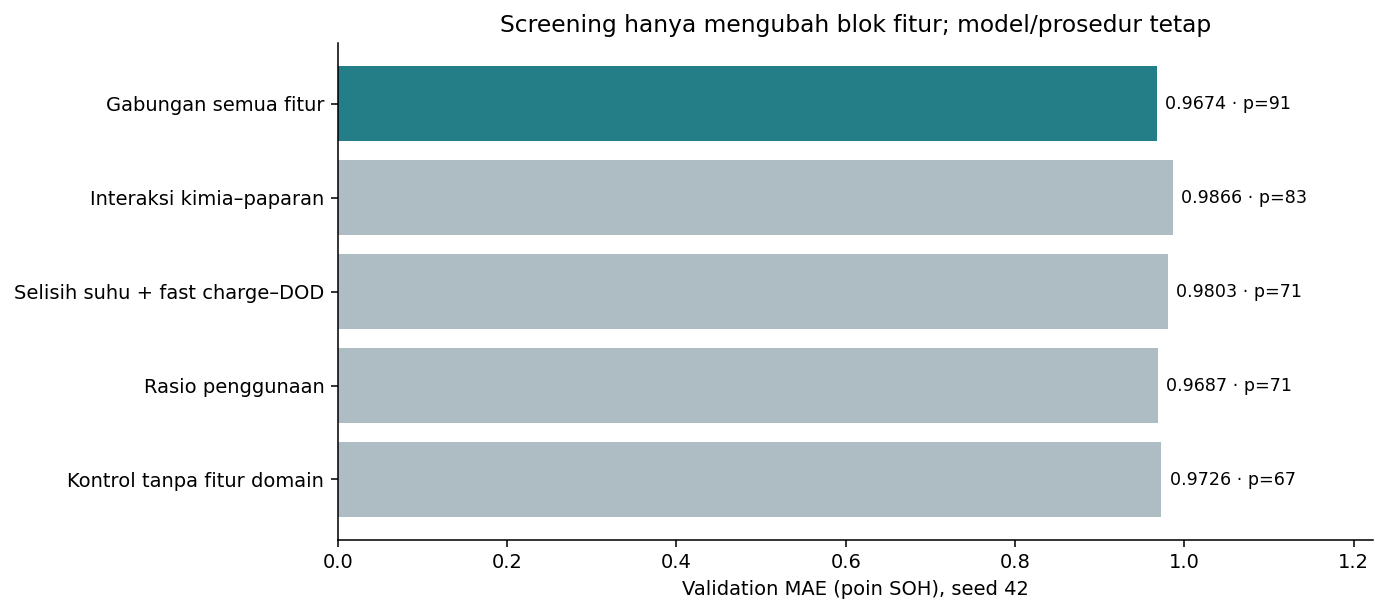

In [6]:
display(tables['screening'])
show('01_feature_screening.png')
assert len(tables['screening'])==5
assert tables['screening'].input_neurons.tolist()==[67,71,71,83,91]

**Temuan:** gabungan fitur memberi MAE screening terendah sekitar 0,9674, sedikit di bawah rasio penggunaan sekitar 0,9687 dan kontrol 0,9726. Konteks atau kimia sendiri justru lebih buruk pada seed tersebut. Jadi tidak semua kelompok fitur otomatis membantu.

Selisih dua varian FE teratas sangat kecil. Sesuai protokol, hanya pemenang screening yang dikonfirmasi tiga seed. Ini tidak membuktikan peringkat semua varian stabil pada seed lain.

## 7. Konfirmasi tiga seed dan besarnya gain

Kontrol dan FE terbaik dibandingkan pada seed 42/123/2026, dengan arsitektur serta prosedur yang sama. Semua seed dilaporkan. SD menggunakan ddof=1 dan bukan confidence interval populasi.

,variant,run_id,seed,input_neurons,parameters,train_mae_pp,validation_mae_pp,validation_rmse_pp,validation_r2,best_epoch,epochs_actual
0,control_no_domain_features,run_417429878fc7,42,67,2209,0.922767,0.972578,1.497313,0.954501,123,126
1,control_no_domain_features,run_312fdc17ada1,123,67,2209,0.928527,0.976105,1.499959,0.954340,116,120
2,control_no_domain_features,run_73d0ae8e6140,2026,67,2209,0.932252,0.977061,1.508048,0.953847,100,115
3,fe_combined,run_e19f105ebb61,42,91,2977,0.916419,0.967377,1.475324,0.955828,70,85
4,fe_combined,run_8cb6dbab0ebb,123,91,2977,0.938465,0.975407,1.491904,0.954829,52,67
5,fe_combined,run_566a4635b293,2026,91,2977,0.915877,0.965350,1.479890,0.955554,61,76


,variant,n_seeds,mae_mean_pp,mae_sd_pp,rmse_mean_pp,r2_mean,parameters
0,control_no_domain_features,3,0.975248,0.002361,1.501773,0.954229,2209
1,fe_combined,3,0.969378,0.005319,1.482373,0.955404,2977


,seed,control_no_domain_features,fe_combined,mae_improvement_pp
0,42,0.972578,0.967377,0.005201
1,123,0.976105,0.975407,0.000698
2,2026,0.977061,0.965350,0.011710


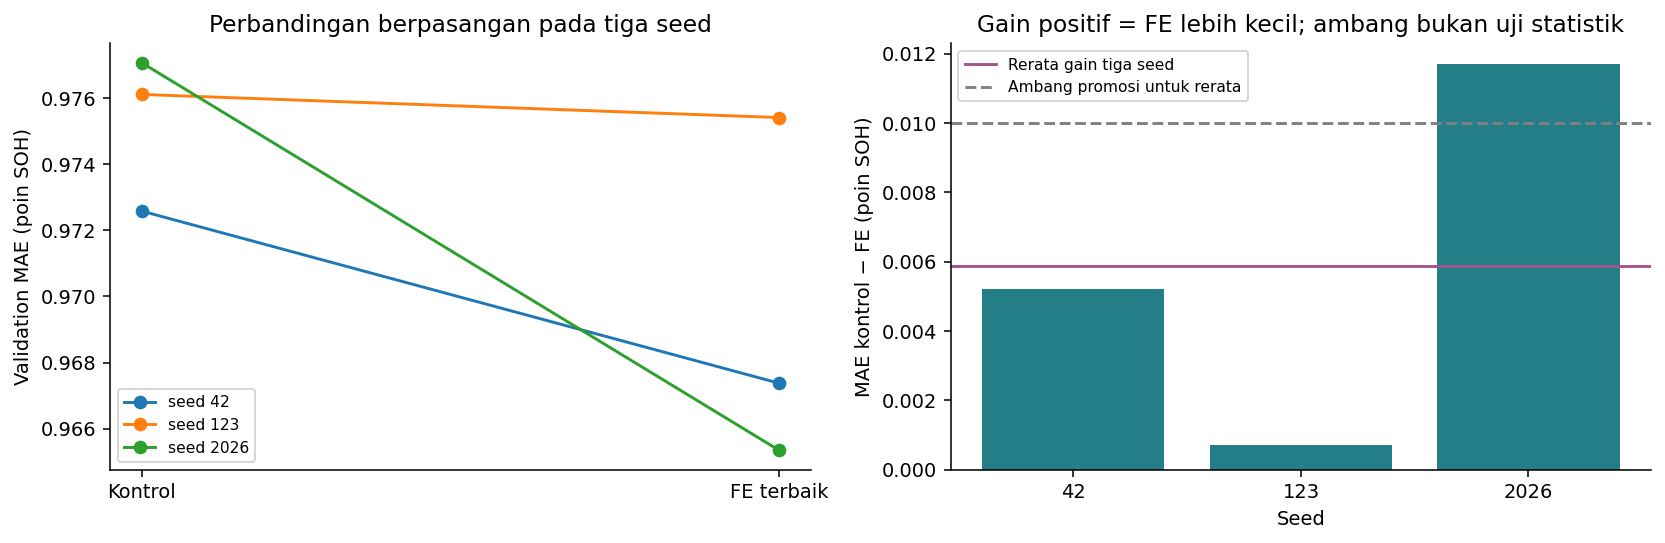

Gain rerata (poin SOH): 0.005869760370646977


In [7]:
display(tables['seed_confirmation'])
display(tables['seed_summary'])
display(tables['paired_seed_improvements'])
show('02_paired_seed_improvements.png')
summary=tables['seed_summary'].set_index('variant')
paired=tables['paired_seed_improvements']
assert np.isclose(paired.mae_improvement_pp.mean(),study['mean_validation_mae_improvement_pp'])
assert paired.mae_improvement_pp.gt(0).sum()==study['seed_wins']
print('Gain rerata (poin SOH):',study['mean_validation_mae_improvement_pp'])

**Temuan:** mean MAE kontrol **0,97525 ± 0,00236**, FE gabungan **0,96938 ± 0,00532** poin SOH. Gain sekitar **0,00587 poin** atau 0,60% relatif terhadap error kontrol, dengan arah positif pada tiga seed.

Meski arahnya konsisten pada seed yang diuji, besarnya gain kecil dan variasi FE lebih besar. Validasi dipakai berulang untuk screening/konfirmasi, jadi hasil belum independen. Tidak memilih seed FE yang paling bagus untuk menutupi yang lain.

## 8. Apakah kondisi SOH rendah terbantu?

Periksa per rentang dengan jumlah observasi/baterai. Rerata dihitung pada tiga seed yang sama. Band bukan kelas baru dan tidak digunakan untuk resampling target.

,variant,band,n_rows,batteries,mae_mean_pp,mae_sd_pp
0,control_no_domain_features,<70,106,28,3.462595,0.075845
1,control_no_domain_features,70–<80,338,80,2.073720,0.033209
2,control_no_domain_features,80–<90,1390,218,1.307472,0.010378
3,control_no_domain_features,90–<95,1814,305,0.953651,0.001784
4,control_no_domain_features,>=95,3851,384,0.700629,0.006180
5,fe_combined,<70,106,28,3.247238,0.065553
6,fe_combined,70–<80,338,80,2.075319,0.029634
7,fe_combined,80–<90,1390,218,1.296319,0.013090
8,fe_combined,90–<95,1814,305,0.967169,0.011532
9,fe_combined,>=95,3851,384,0.692644,0.005857


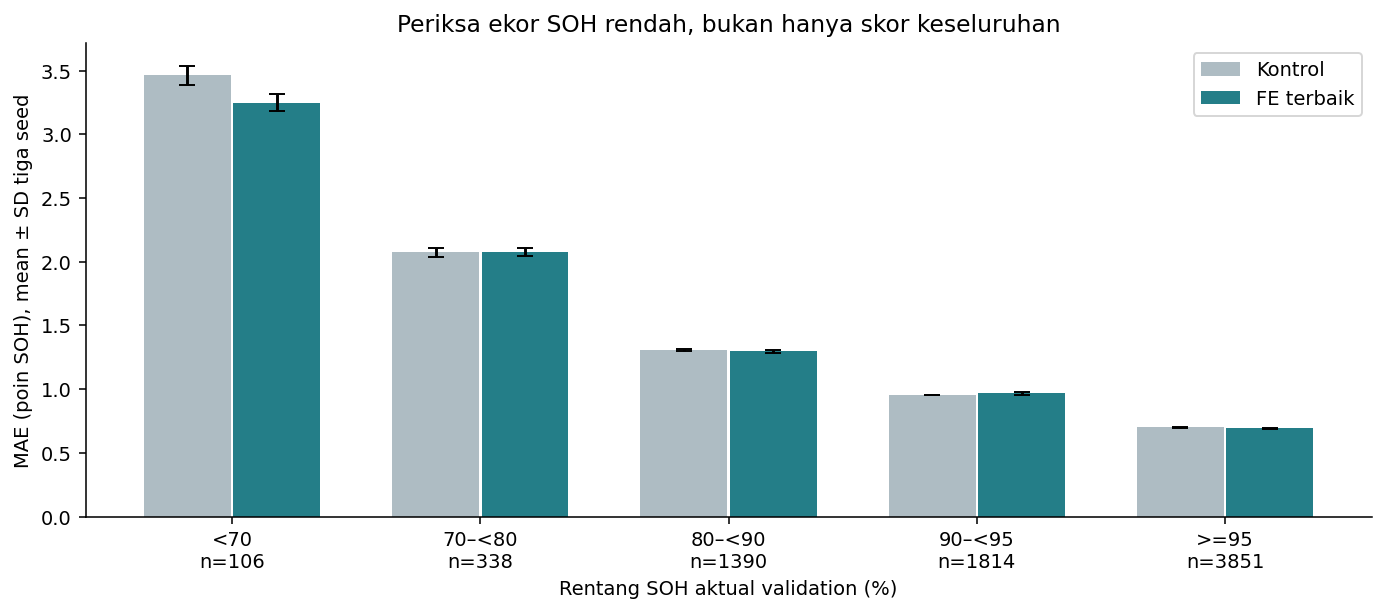

In [8]:
band_summary=pd.read_csv(output/'validation_band_summary.csv')
display(band_summary)
show('03_validation_tail_errors.png')
for variant,group in tables['validation_bands'].groupby('variant'):
    assert group.groupby('seed').rows.sum().eq(7499).all()

**Temuan:** pada SOH <70%, mean MAE turun dari sekitar **3,463 menjadi 3,247 poin** (106 observasi, 28 baterai). Itu manfaat yang lebih terlihat daripada gain agregat. Namun tidak semua rentang membaik: SOH 90–<95% sedikit memburuk.

Manfaat ekor ini tetap perlu dibaca sebagai temuan validation dengan dukungan terbatas. Tidak mengganti kriteria promosi setelah melihat satu kelompok yang menarik.

## 9. Kompleksitas dan keputusan

Aturan sebelum training mensyaratkan gain rerata ≥0,01 poin SOH dan kemenangan minimal dua seed. Hasil memenuhi syarat arah seed tetapi belum memenuhi batas besarnya gain. Parameter bertambah dari 2.209 menjadi 2.977 (+34,8%).

Karena itu **kontrol kandidat 03 tetap kandidat utama menurut aturan praktis study ini**. FE gabungan disimpan sebagai alternatif dan hasil ablation yang sah. Ini tidak berarti semua feature engineering sia-sia atau perbaikan statistik pasti tidak ada; threshold ini bukan uji signifikansi.

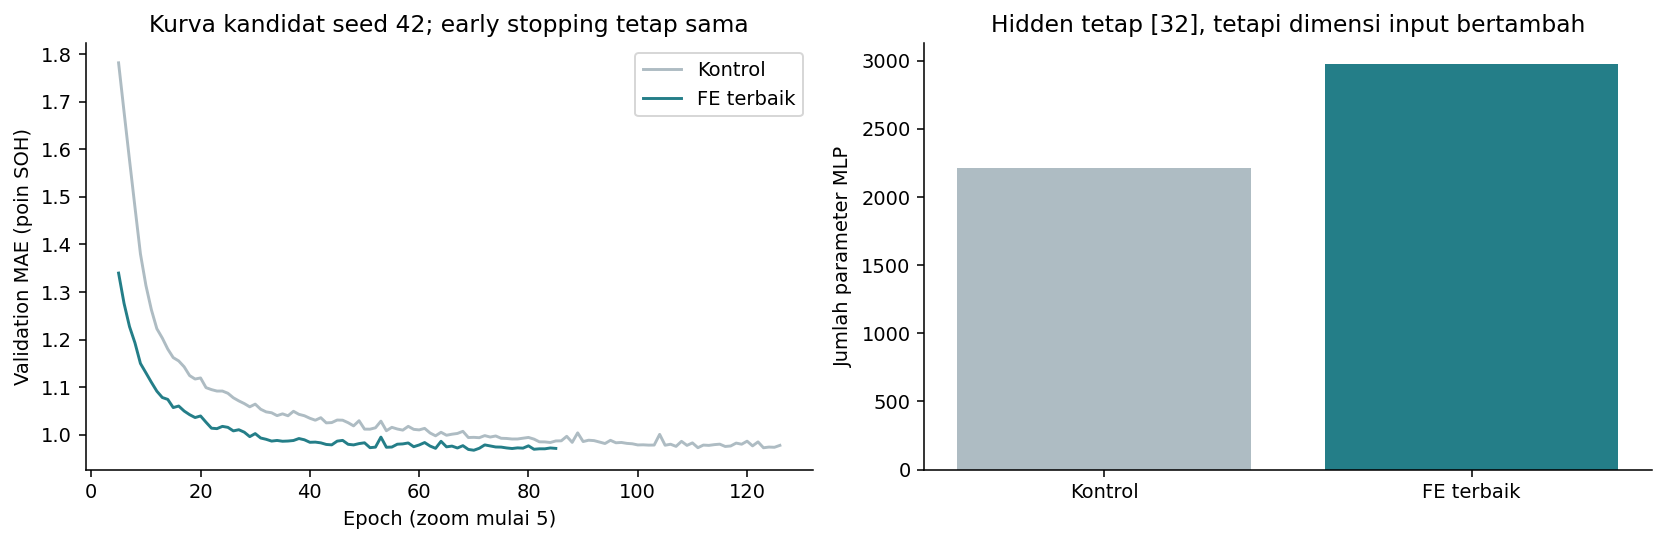

Rekomendasi: control_no_domain_features promosi: False


In [9]:
show('04_learning_and_complexity.png')
expected=(study['mean_validation_mae_improvement_pp']>=settings['minimum_mean_mae_improvement_pp'] and study['seed_wins']>=settings['minimum_seed_wins'])
assert expected==study['promoted_by_prespecified_gate']
assert study['recommendation']=='control_no_domain_features'
print('Rekomendasi:',study['recommendation'],'promosi:',study['promoted_by_prespecified_gate'])

## 10. Penyimpanan pipeline dan kecocokan checkpoint

Bundle inference memuat base+transformasi ekstra, target scaler, nama fitur, dan provenance. Fingerprint memakai nilai parameter yang dipelajari secara eksplisit, bukan bentuk alias objek saat pickle, agar stabil setelah serialisasi.

Array dan bundle tetap lokal. Checkpoint MLP memakai training loop yang sama; config/history/summary/status dibagikan. Studi asli 03 dan preprocessing lama tidak ditulis ulang.

In [10]:
data=load_engineered_data(best,ROOT)
state=pipeline_state_fingerprint(data['bundle']['preprocessor'],data['bundle']['target_scaler'])
assert state==data['bundle']['state_hash']
run_id=tables['screening'].set_index('variant').loc[best,'run_id']
metadata=json.loads((ROOT/'results/experiments/runs'/run_id/'summary.json').read_text(encoding='utf-8'))
model,_=load_checkpoint(ROOT/metadata['checkpoint_best'],data)
pred=original_scale(predict_scaled(model,torch.from_numpy(data['validation']['X'])),data['bundle'])
mae=np.abs(pred-data['validation']['y_original']).mean()
assert np.isclose(mae,metadata['validation']['mae'])
print('PASS: pipeline tersimpan dan checkpoint FE cocok serta mereproduksi validation MAE.')

PASS: pipeline tersimpan dan checkpoint FE cocok serta mereproduksi validation MAE.


## 11. Pengujian dan provenance

Test memeriksa rumus/unit, denominator nol, missing, kimia baru, prefix base yang identik, parameter train-only, input target/ID yang ditolak, serialisasi, fingerprint perubahan parameter, serta independensi urutan baris. Test MLP/preprocessing sebelumnya tetap dijalankan.

In [11]:
checked=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,capture_output=True,text=True)
print(checked.stdout+checked.stderr)
assert checked.returncode==0
assert study['source_sha256']==hashlib.sha256((ROOT/'src/feature_engineering.py').read_bytes()).hexdigest()
assert study['settings_sha256']==hashlib.sha256((ROOT/'configs/feature_engineering.json').read_bytes()).hexdigest()
assert not study['test_arrays_loaded'] and not study['test_transformed']
assert len(report['figures'])==4
print('PASS: versi kode/config sesuai, tidak memakai test, seluruh pengujian lolos.')

START run_39e7454aa5e6 probe hidden=[4] relu/mse seed=8
DONE run_39e7454aa5e6: best epoch=4/4, val MAE=7.0634, train MAE=7.0634, seconds=0.0
test_extra_fit_is_train_only_and_validation_transform_does_not_refit (test_feature_engineering.FeatureEngineeringTests.test_extra_fit_is_train_only_and_validation_transform_does_not_refit) ... ok
test_fingerprint_detects_changed_learned_scaling (test_feature_engineering.FeatureEngineeringTests.test_fingerprint_detects_changed_learned_scaling) ... ok
test_first_base_columns_and_base_state_are_preserved_exactly (test_feature_engineering.FeatureEngineeringTests.test_first_base_columns_and_base_state_are_preserved_exactly) ... ok
test_formula_values_and_units (test_feature_engineering.FeatureEngineeringTests.test_formula_values_and_units) ... ok
test_nonpositive_denominators_and_missing_operands_stay_missing (test_feature_engineering.FeatureEngineeringTests.test_nonpositive_denominators_and_missing_operands_stay_missing) ... ok
test_serialization_and_

## 12. Reproduksi dan kelanjutan

```powershell
python -m src.feature_engineering
python -m src.feature_reporting
python scripts/run_notebook.py notebooks/03b_feature_engineering_ablation.ipynb --timeout 3600
python scripts/export_eda.py --stage features
```

Sel notebook juga dapat menjalankan study/report secara langsung. Clone baru membutuhkan CSV, artefak preprocessing, dan training ulang jika checkpoint belum tersedia.

Untuk data baru: muat bundle `models/feature_engineering/<variant>.joblib` yang tepercaya, lalu `bundle['preprocessor'].transform(new_rows[bundle['required_columns']])`. Untuk CV, base dan ekstra harus di-fit pada tiap fold-train.

Artefak utama: `results/feature_engineering/FEATURE_ENGINEERING_REPORT.md`, HTML baca, screening, paired-seed improvements, parameter train, dan error per rentang. Test akhir notebook 04 hanya dilakukan setelah pilihan konfigurasi/seed disepakati. Jangan mengubah fitur atau ambang dari hasil test.